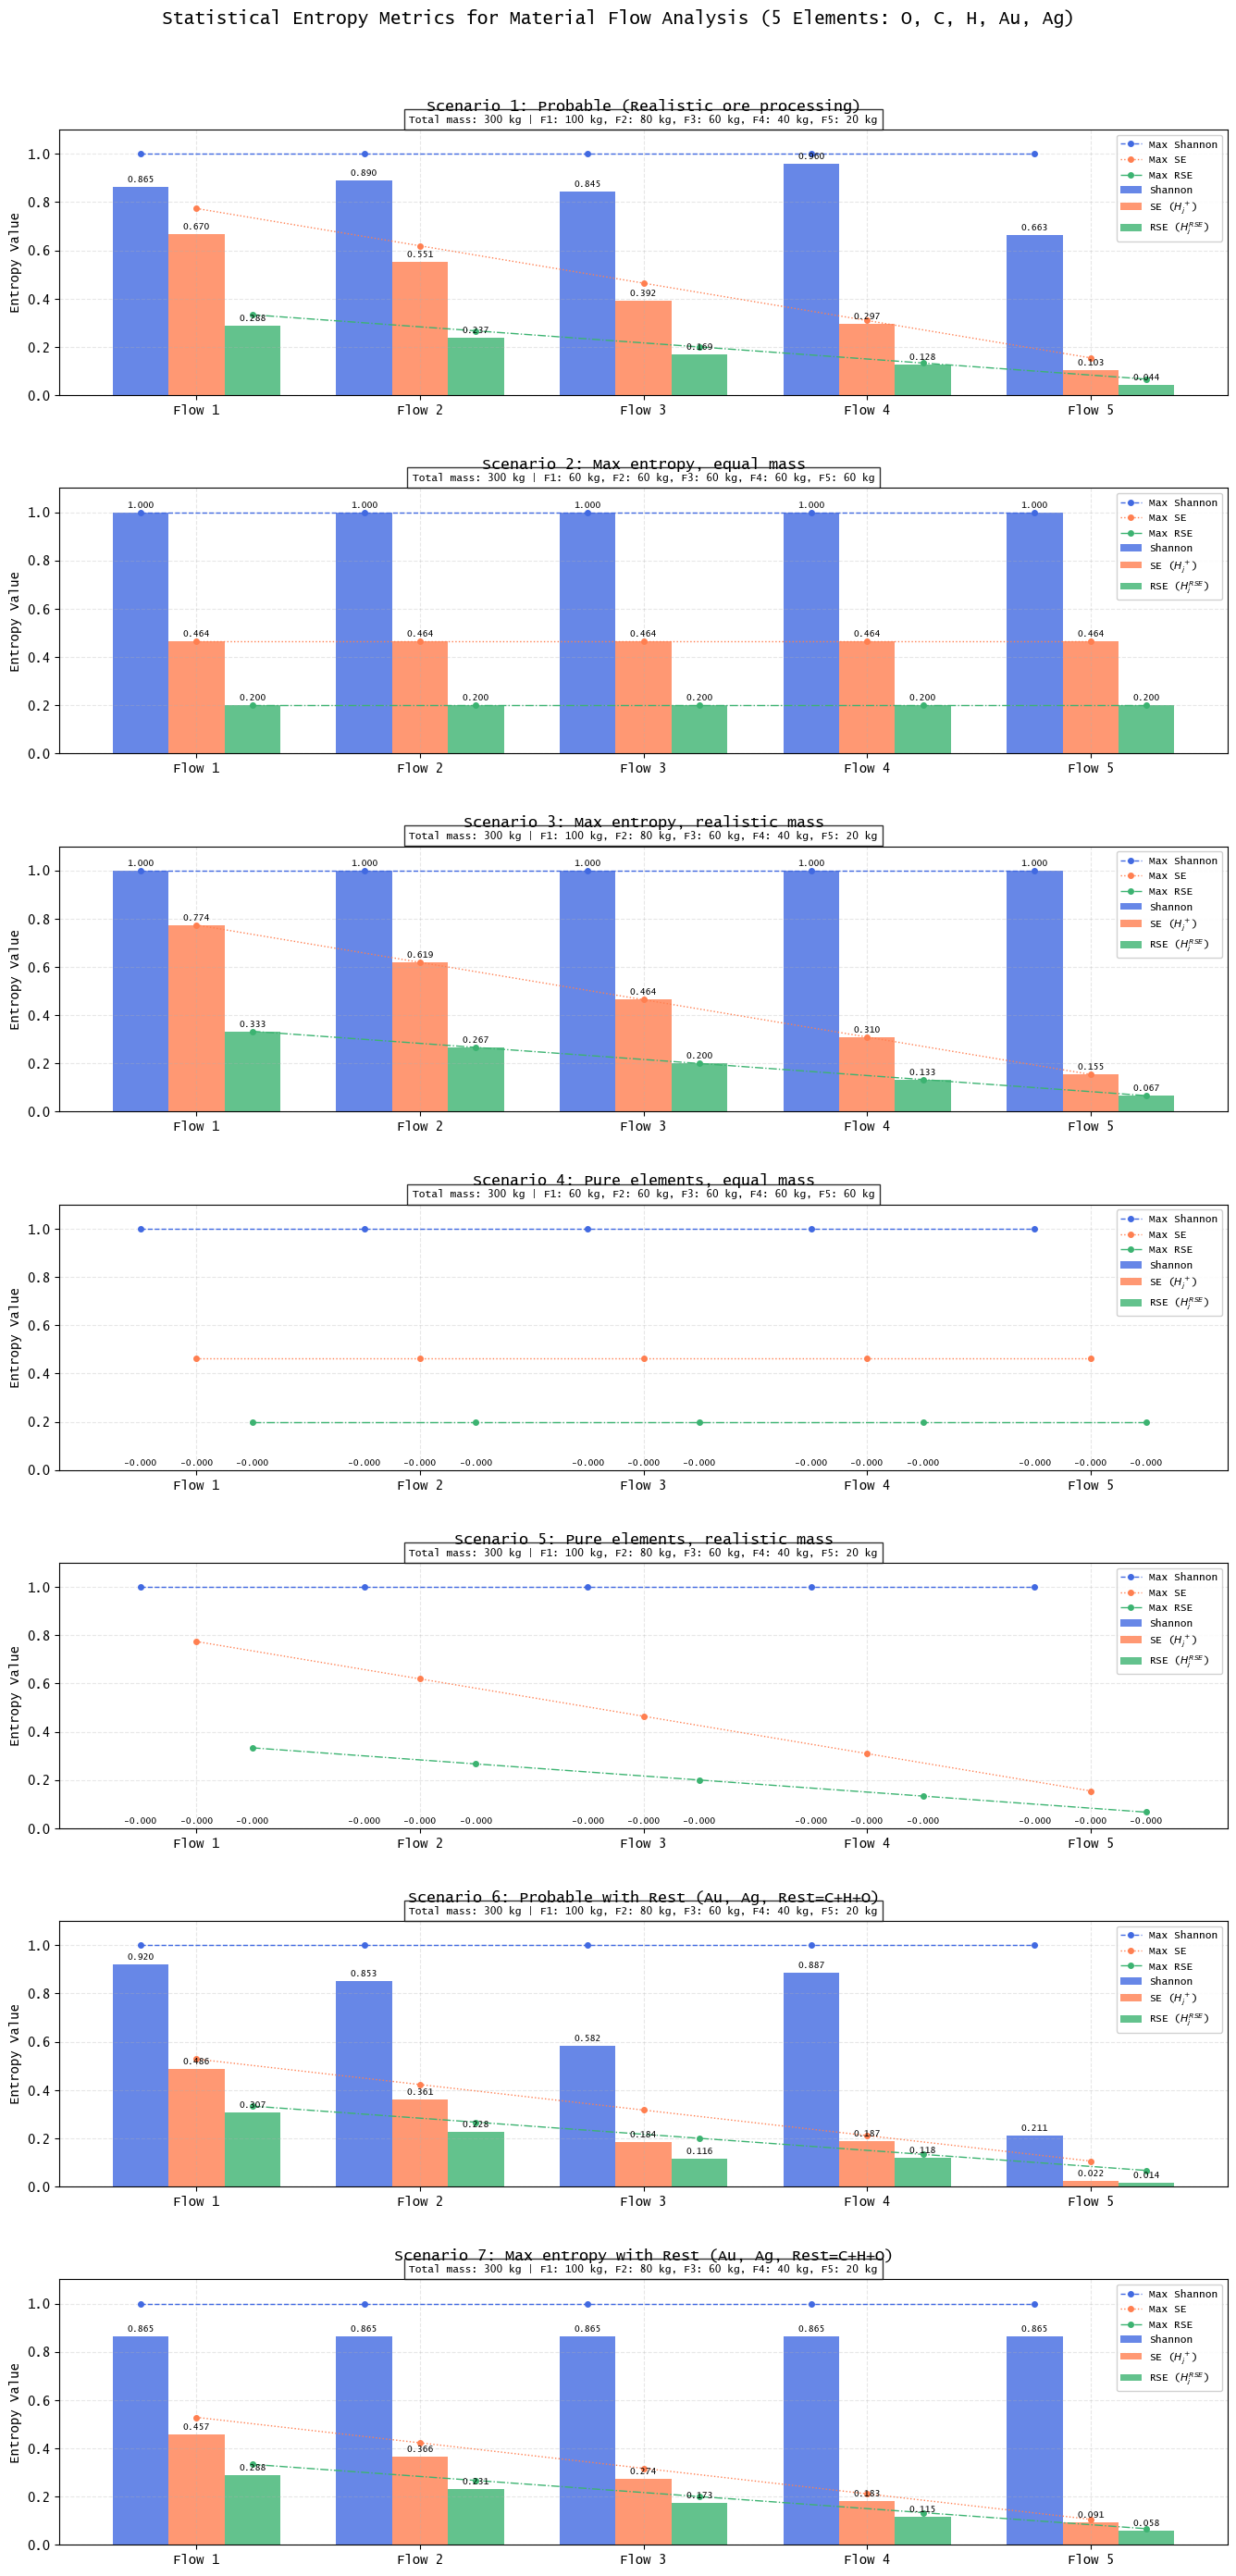

SUMMARY OF SCENARIOS

Scenario 1: Probable (Realistic ore processing)
-----------------------------------------------
Flow   Mass (kg)  Shannon      SE           RSE         
--------------------------------------------------
1      100.0      0.8651       0.6696       0.2884      
2      80.0       0.8898       0.5509       0.2373      
3      60.0       0.8445       0.3922       0.1689      
4      40.0       0.9596       0.2971       0.1280      
5      20.0       0.6628       0.1026       0.0442      

Total SE for stage: 2.0124
Total RSE for stage: 0.8667

Scenario 2: Max entropy, equal mass
-----------------------------------
Flow   Mass (kg)  Shannon      SE           RSE         
--------------------------------------------------
1      60.0       1.0000       0.4644       0.2000      
2      60.0       1.0000       0.4644       0.2000      
3      60.0       1.0000       0.4644       0.2000      
4      60.0       1.0000       0.4644       0.2000      
5      60.0       1.0000

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"]    = "monospace"
plt.rcParams["font.monospace"] = ["Lucida Console", "DejaVu Sans Mono"]

# =============================================================================
# PARAMETERS
# =============================================================================
N_ELEMENTS = 5  # O, C, H, Au, Ag
N_FLOWS = 5

# =============================================================================
# SCENARIO DEFINITIONS
# =============================================================================

scenarios = {
    # Scenario 1: Probable - Realistic gold-silver ore processing inputs
    # Description: A typical processing stage with 5 input streams of varying
    # composition and mass flow rates. This represents a plausible real-world
    # scenario where different ore types and recycled materials enter the process.
    "Scenario 1: Probable (Realistic ore processing)": {
        "mass_flows": np.array([100, 80, 60, 40, 20]),  # kg
        "concentrations": np.array([
            [0.30, 0.10, 0.05, 0.40, 0.15],  # Flow 1: Rich primary ore (high Au)
            [0.40, 0.15, 0.05, 0.25, 0.15],  # Flow 2: Medium-grade ore
            [0.50, 0.20, 0.10, 0.10, 0.10],  # Flow 3: Low-grade ore
            [0.25, 0.20, 0.10, 0.30, 0.15],  # Flow 4: Recycled concentrate
            [0.60, 0.25, 0.10, 0.03, 0.02]   # Flow 5: Flux material (mostly gangue)
        ])
    },
    
    # Scenario 2: Maximum entropy, equal mass flows
    # All elements equally distributed (1/5 each) with identical mass flows
    "Scenario 2: Max entropy, equal mass": {
        "mass_flows": np.array([60, 60, 60, 60, 60]),
        "concentrations": np.tile([1/N_ELEMENTS] * N_ELEMENTS, (N_FLOWS, 1))
    },
    
    # Scenario 3: Maximum entropy, mass flows from Scenario 1
    # All elements equally distributed but with realistic mass distribution
    "Scenario 3: Max entropy, realistic mass": {
        "mass_flows": np.array([100, 80, 60, 40, 20]),
        "concentrations": np.tile([1/N_ELEMENTS] * N_ELEMENTS, (N_FLOWS, 1))
    },
    
    # Scenario 4: Strictly concentrated, equal mass flows
    # Each flow contains only one element at 100% concentration
    "Scenario 4: Pure elements, equal mass": {
        "mass_flows": np.array([60, 60, 60, 60, 60]),
        "concentrations": np.eye(N_ELEMENTS)
    },
    
    # Scenario 5: Strictly concentrated, mass flows from Scenario 1
    # Each flow contains only one element with realistic mass distribution
    "Scenario 5: Pure elements, realistic mass": {
        "mass_flows": np.array([100, 80, 60, 40, 20]),
        "concentrations": np.eye(N_ELEMENTS)
    },

    "Scenario 6: Probable with Rest (Au, Ag, Rest=C+H+O)": {
        "mass_flows": np.array([100, 80, 60, 40, 20]),
        "concentrations": np.array([
            [0.40, 0.15, 0.45], [0.25, 0.15, 0.60],
            [0.10, 0.10, 0.80], [0.30, 0.15, 0.55], [0.03, 0.02, 0.95]
        ])
    },
    "Scenario 7: Max entropy with Rest (Au, Ag, Rest=C+H+O)": {
        "mass_flows": np.array([100, 80, 60, 40, 20]),
        "concentrations": np.tile([0.2, 0.2, 0.6], (N_FLOWS, 1))
    }
}


# =============================================================================
# METRIC CALCULATIONS
# =============================================================================

def calculate_metrics(mass_flows, concentrations):
    """
    Calculate Shannon entropy, SE, and RSE for each flow.
    
    Args:
        mass_flows: Array of mass flows for each flow (kg)
        concentrations: 2D array of element concentrations (flows x elements)
    
    Returns:
        shannon: Shannon entropy per flow (ignores mass contribution)
        se: Statistical Entropy per flow (H_j^+)
        rse: Relative Statistical Entropy per flow (H_j^RSE)
        max_shannon: Maximum possible Shannon per flow (always 1)
        max_se: Maximum possible SE per flow (depends on mass fraction)
        max_rse: Maximum possible RSE per flow (depends on mass fraction)
    """
    n_flows = len(mass_flows)
    total_mass = np.sum(mass_flows)
    n_elements = concentrations.shape[1]
    
    shannon = np.zeros(n_flows)
    se = np.zeros(n_flows)
    rse = np.zeros(n_flows)
    max_se = np.zeros(n_flows)
    max_rse = np.zeros(n_flows)
    
    mass_fractions = mass_flows / total_mass
    
    for j in range(n_flows):
        c = concentrations[j]
        c_pos = c[c > 0]  # Only positive concentrations
        
        if len(c_pos) == 0:
            # Edge case: all concentrations zero
            shannon[j] = 0
            se[j] = 0
            rse[j] = 0
        else:
            # Shannon entropy (base n_elements, ignores mass)
            shannon[j] = -np.sum(c_pos * np.log(c_pos) / np.log(n_elements))
            
            # SE (Statistical Entropy, base 2, includes mass fraction)
            se[j] = -mass_fractions[j] * np.sum(c_pos * np.log2(c_pos))
            
            # RSE (Relative Statistical Entropy, base n_elements, includes mass fraction)
            rse[j] = -mass_fractions[j] * np.sum(c_pos * np.log(c_pos) / np.log(n_elements))
        
        # Maximum potential values for this flow
        max_se[j] = mass_fractions[j] * np.log2(n_elements)  # When all c_i = 1/n_elements
        max_rse[j] = mass_fractions[j] * 1.0  # When all c_i = 1/n_elements
    
    return shannon, se, rse, np.ones(n_flows), max_se, max_rse

# =============================================================================
# PLOTTING
# =============================================================================

def plot_scenarios(scenarios):
    """Create subplots for each scenario showing Shannon, SE, and RSE."""
    n_scenarios = len(scenarios)
    fig, axes = plt.subplots(n_scenarios, 1, figsize=(14, 4 * n_scenarios + 1))
    
    if n_scenarios == 1:
        axes = [axes]
    
    colors = {'Shannon': 'royalblue', 'SE': 'coral', 'RSE': 'mediumseagreen'}
    line_styles = {'Shannon': '--', 'SE': ':', 'RSE': '-.'}
    
    flow_labels = [f'Flow {j+1}' for j in range(N_FLOWS)]
    
    for idx, (scenario_name, data) in enumerate(scenarios.items()):
        ax = axes[idx]
        mass_flows = data['mass_flows']
        concentrations = data['concentrations']
        
        shannon, se, rse, max_shannon, max_se, max_rse = calculate_metrics(mass_flows, concentrations)
        
        # Plot positions
        x = np.arange(N_FLOWS)
        width = 0.25
        
        # Plot bars
        ax.bar(x - width, shannon, width, label='Shannon', color=colors['Shannon'], alpha=0.8)
        ax.bar(x, se, width, label='SE ($H_j^+$)', color=colors['SE'], alpha=0.8)
        ax.bar(x + width, rse, width, label='RSE ($H_j^{RSE}$)', color=colors['RSE'], alpha=0.8)
        
        # Plot maximum potential lines
        ax.plot(x - width, max_shannon, 'o--', color=colors['Shannon'], 
                linewidth=1, markersize=4, label='Max Shannon')
        ax.plot(x, max_se, 'o:', color=colors['SE'], 
                linewidth=1, markersize=4, label='Max SE')
        ax.plot(x + width, max_rse, 'o-.', color=colors['RSE'], 
                linewidth=1, markersize=4, label='Max RSE')
        
        # Annotations for mass flows and total mass
        total_mass = np.sum(mass_flows)
        mass_text = f"Total mass: {total_mass} kg | "
        mass_text += ", ".join([f"F{j+1}: {m} kg" for j, m in enumerate(mass_flows)])
        ax.text(0.5, 1.02, mass_text, ha='center', va='bottom', 
                transform=ax.transAxes, fontsize=8, bbox=dict(facecolor='white', alpha=0.8))
        
        # Formatting
        ax.set_title(scenario_name, fontsize=12, fontweight='bold', pad=15)
        ax.set_xticks(x)
        ax.set_xticklabels(flow_labels)
        ax.set_ylabel('Entropy Value', fontsize=10)
        ax.set_ylim(0, 1.1 * max(np.max(shannon), np.max(se), np.max(rse), 
                                 np.max(max_shannon), np.max(max_se), np.max(max_rse)))
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
        
        # Add value labels on bars
        for i, (s, e, r) in enumerate(zip(shannon, se, rse)):
            ax.text(i - width, s + 0.02, f'{s:.3f}', ha='center', fontsize=7)
            ax.text(i, e + 0.02, f'{e:.3f}', ha='center', fontsize=7)
            ax.text(i + width, r + 0.02, f'{r:.3f}', ha='center', fontsize=7)
    
    plt.tight_layout(pad=3.0)
    return fig

# =============================================================================
# EXECUTE AND DISPLAY
# =============================================================================

# Generate plots
fig = plot_scenarios(scenarios)

# Add overall title and description
fig.suptitle('Statistical Entropy Metrics for Material Flow Analysis (5 Elements: O, C, H, Au, Ag)',
             fontsize=14, fontweight='bold', y=0.995)

plt.subplots_adjust(top=0.95, bottom=0.05, hspace=0.35)
plt.savefig("entropy_comparison.svg")
# plt.savefig("entropy_comparison.png")
plt.show()

# =============================================================================
# PRINT SUMMARY TABLE
# =============================================================================

print("="*100)
print("SUMMARY OF SCENARIOS")
print("="*100)

for scenario_name, data in scenarios.items():
    print(f"\n{scenario_name}")
    print("-" * len(scenario_name))
    mass_flows = data['mass_flows']
    concentrations = data['concentrations']
    shannon, se, rse, _, _, _ = calculate_metrics(mass_flows, concentrations)
    
    print(f"{'Flow':<6} {'Mass (kg)':<10} {'Shannon':<12} {'SE':<12} {'RSE':<12}")
    print("-" * 50)
    for j in range(N_FLOWS):
        print(f"{j+1:<6} {mass_flows[j]:<10.1f} {shannon[j]:<12.4f} {se[j]:<12.4f} {rse[j]:<12.4f}")
    
    total_se = np.sum(se)
    total_rse = np.sum(rse)
    print(f"\nTotal SE for stage: {total_se:.4f}")
    print(f"Total RSE for stage: {total_rse:.4f}")

print("\n" + "="*100)
print("THEORETICAL MAXIMA (for reference)")
print("="*100)
print(f"Maximum Shannon per flow (all c_i = 1/{N_ELEMENTS}): 1.0")
print(f"Maximum SE per flow (all c_i = 1/{N_ELEMENTS}, M_j = M_stage): {np.log2(N_ELEMENTS):.4f}")
print(f"Maximum RSE per flow (all c_i = 1/{N_ELEMENTS}, M_j = M_stage): 1.0")
print(f"Maximum total SE for stage: {np.log2(N_ELEMENTS):.4f}")
print(f"Maximum total RSE for stage: 1.0")

# focus on rest fraction

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


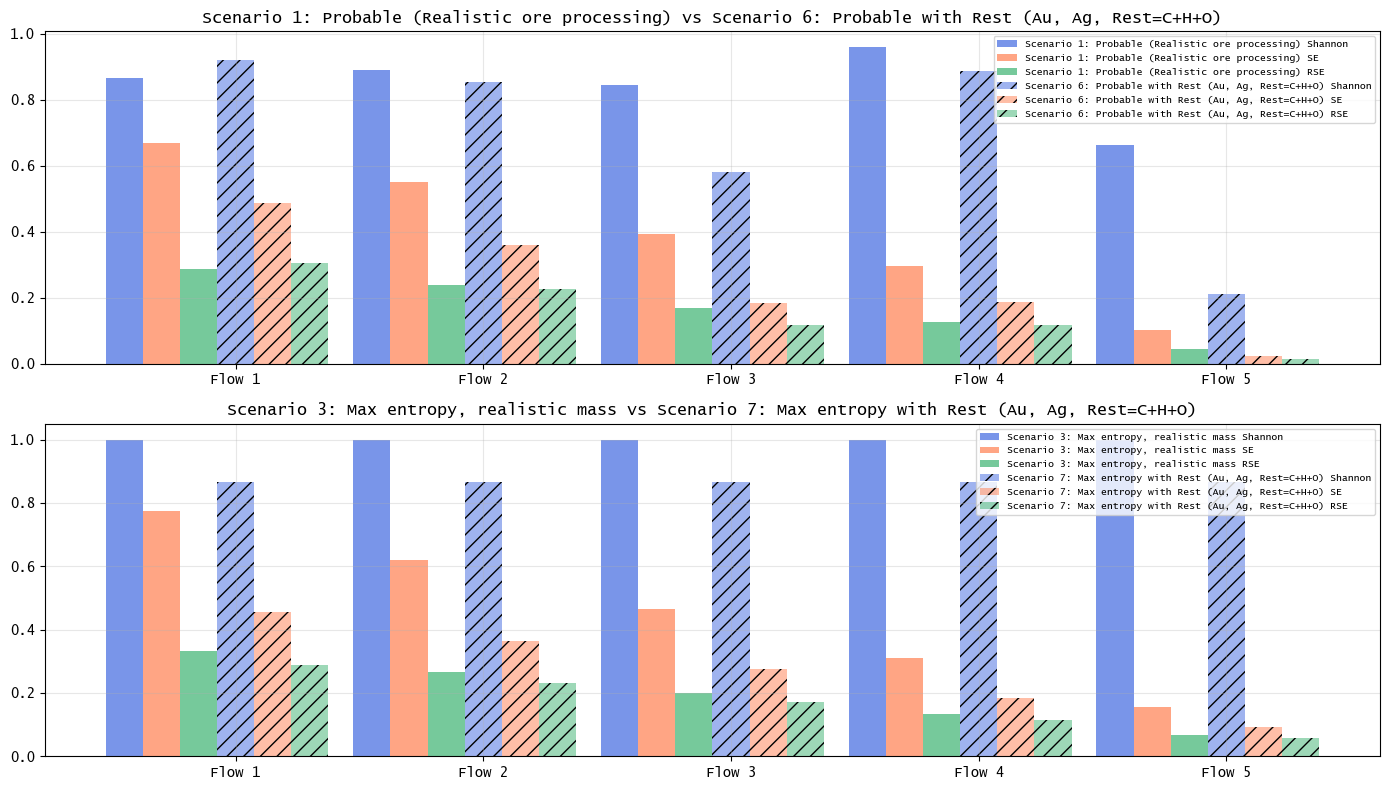

In [4]:
# Add this function and call it at the end:
def plot_comparison(scenarios, pairs):
    fig, axes = plt.subplots(len(pairs), 1, figsize=(14, 8))
    if len(pairs) == 1: axes = [axes]
    colors = {'Shannon': 'royalblue', 'SE': 'coral', 'RSE': 'mediumseagreen'}
    for idx, (n1, n2) in enumerate(pairs):
        ax = axes[idx]
        d1, d2 = scenarios[n1], scenarios[n2]
        s1, se1, rse1, _, _, _ = calculate_metrics(d1['mass_flows'], d1['concentrations'])
        s2, se2, rse2, _, _, _ = calculate_metrics(d2['mass_flows'], d2['concentrations'])
        x = np.arange(N_FLOWS); w = 0.15
        ax.bar(x-w*2, s1, w, label=f'{n1} Shannon', color=colors['Shannon'], alpha=0.7)
        ax.bar(x-w, se1, w, label=f'{n1} SE', color=colors['SE'], alpha=0.7)
        ax.bar(x, rse1, w, label=f'{n1} RSE', color=colors['RSE'], alpha=0.7)
        ax.bar(x+w, s2, w, label=f'{n2} Shannon', color=colors['Shannon'], alpha=0.5, hatch='//')
        ax.bar(x+w*2, se2, w, label=f'{n2} SE', color=colors['SE'], alpha=0.5, hatch='//')
        ax.bar(x+w*3, rse2, w, label=f'{n2} RSE', color=colors['RSE'], alpha=0.5, hatch='//')
        ax.set_title(f'{n1} vs {n2}'); ax.set_xticks(x+w); ax.set_xticklabels([f'Flow {j+1}' for j in range(N_FLOWS)])
        ax.grid(True, alpha=0.3); ax.legend(fontsize=7)
    plt.tight_layout(); return fig

# Call after your main plot:
comparison_pairs = [
    ("Scenario 1: Probable (Realistic ore processing)", "Scenario 6: Probable with Rest (Au, Ag, Rest=C+H+O)"),
    ("Scenario 3: Max entropy, realistic mass", "Scenario 7: Max entropy with Rest (Au, Ag, Rest=C+H+O)")
]
fig_comp = plot_comparison(scenarios, comparison_pairs)
plt.savefig("comparison_plot.eps")
plt.savefig("comparison_plot.svg")
plt.show()